# Olist E-Commerce Customer Behaviour and Retention Analytics

## 1. Introduction

This notebook analyzes customer purchasing behaviour using the Olist Brazilian E-Commerce dataset.

The main objectives are:

- Analyze customer purchasing patterns.
- Identify one-time and repeat customers.
- Calculate customer revenue and purchase frequency.
- Perform RFM (Recency, Frequency, Monetary) segmentation.
- Analyze customer cohorts and retention.
- Generate actionable business insights.

The analysis uses cleaned datasets stored in the data/processed directory.

## 2. Importing Required Libraries

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading Cleaned Datasets

In [20]:
PROCESSED_PATH = Path("../data/processed")

customers = pd.read_csv(PROCESSED_PATH / "customers_cleaned.csv")
orders = pd.read_csv(PROCESSED_PATH / "orders_cleaned.csv")
order_items = pd.read_csv(PROCESSED_PATH / "order_items_cleaned.csv")
order_payments = pd.read_csv(PROCESSED_PATH / "order_payments_cleaned.csv")
order_reviews = pd.read_csv(PROCESSED_PATH / "order_reviews_cleaned.csv")

# Convert order timestamps

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

print("Customer analytics datasets loaded successfully!")

Customer analytics datasets loaded successfully!


## 4. Preparing Customer Purchase Data

For customer purchase and revenue analysis, only delivered orders are considered. This ensures that canceled and undelivered orders do not inflate completed purchase metrics.

In [21]:
# Select delivered orders

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Merge customers with delivered orders

customer_orders = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id",
    how="left"
)

print("Delivered orders:", len(delivered_orders))
print("Customer-order records:", len(customer_orders))

display(customer_orders.head())

Delivered orders: 96478
Customer-order records: 96478


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_missing,approval_date_missing,customer_unique_id,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,7c396fd4830fd04220f754e42b4e5bff,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,af07308b275d755c9edb36a90c618231,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,3a653a41f6f9fc3d2a113cf8398680e8,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,7c142cf63193a1473d2e66489a9ae977,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,72632f0f9dd73dfee390c9b22eb56dd6,SP


## 5. Customer Purchase Frequency

Calculate the number of delivered orders made by each unique customer. Classify customers as one-time or repeat purchasers.

In [22]:
customer_frequency = (
    customer_orders.groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index(name="frequency")
)

customer_frequency["customer_type"] = np.where(
    customer_frequency["frequency"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

display(customer_frequency.head())

# Customer type summary

customer_type_summary = (
    customer_frequency["customer_type"]
    .value_counts()
    .reset_index()
)

customer_type_summary.columns = ["Customer Type", "Customer Count"]

customer_type_summary["Percentage"] = (
    customer_type_summary["Customer Count"]
    / customer_type_summary["Customer Count"].sum()
) * 100

display(customer_type_summary)

,customer_unique_id,frequency,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,One-Time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,One-Time Customer
2,0000f46a3911fa3c0805444483337064,1,One-Time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,One-Time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,One-Time Customer


,Customer Type,Customer Count,Percentage
0,One-Time Customer,90557,97.00
1,Repeat Customer,2801,3.00


## 6. One-Time vs Repeat Customer Analysis

Visualize the proportion of one-time and repeat customers to understand customer loyalty.

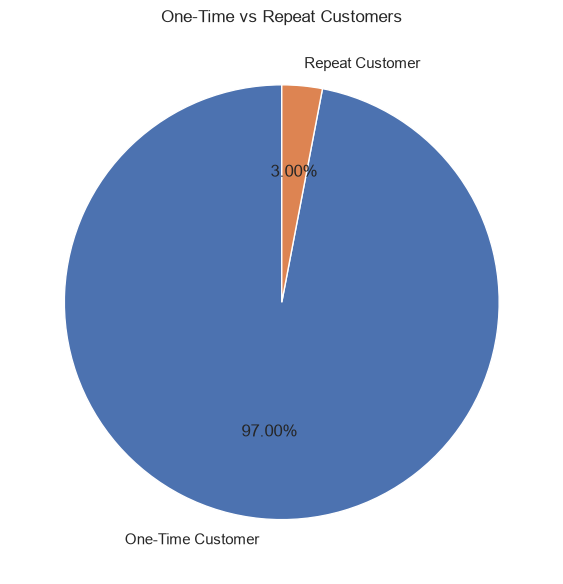

In [23]:
plt.figure(figsize=(8, 6))

plt.pie(
    customer_type_summary["Customer Count"],
    labels=customer_type_summary["Customer Type"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("One-Time vs Repeat Customers")
plt.tight_layout()
plt.show()

In [24]:
# Check missing customer identifiers after merging

print("Missing customer IDs:",
      customer_orders["customer_id"].isna().sum())

print("Missing unique customer IDs:",
      customer_orders["customer_unique_id"].isna().sum())

print("Missing customer states:",
      customer_orders["customer_state"].isna().sum())

# Inspect any unmatched records
display(
    customer_orders[
        customer_orders["customer_unique_id"].isna()
    ].head(10)
)

Missing customer IDs: 0
Missing unique customer IDs: 0
Missing customer states: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_missing,approval_date_missing,customer_unique_id,customer_state


## 7. Customer Monetary Value Analysis

Calculate the total product revenue generated by each unique customer using delivered orders. Product prices exclude freight charges.

In [25]:
# Aggregate order-item prices at order level

order_revenue = (
    order_items.groupby("order_id")["price"]
    .sum()
    .reset_index(name="order_revenue")
)

# Join delivered orders with order revenue

customer_revenue_data = customer_orders.merge(
    order_revenue,
    on="order_id",
    how="inner"
)

# Calculate revenue per unique customer

customer_monetary = (
    customer_revenue_data.groupby("customer_unique_id")["order_revenue"]
    .sum()
    .reset_index(name="monetary")
)

display(customer_monetary.head())

print("Total delivered product revenue: R$",
      round(customer_monetary["monetary"].sum(), 2))

print("Average customer spending: R$",
      round(customer_monetary["monetary"].mean(), 2))

,customer_unique_id,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90
2,0000f46a3911fa3c0805444483337064,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,25.99
4,0004aac84e0df4da2b147fca70cf8255,180.00


Total delivered product revenue: R$ 13221498.11
Average customer spending: R$ 141.62


In [26]:
# Reference date: one day after the latest purchase date
reference_date = (
    delivered_orders["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Combine customer purchase date, order frequency and revenue
customer_rfm = (
    customer_revenue_data
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_revenue", "sum")
    )
    .reset_index()
)

# Calculate recency in days
customer_rfm["recency"] = (
    reference_date - customer_rfm["last_purchase"]
).dt.days

# Arrange columns
customer_rfm = customer_rfm[
    ["customer_unique_id", "recency", "frequency", "monetary"]
]

# Display results
print("RFM Analysis Summary")
display(customer_rfm.head())

print("\nRFM Statistics")
display(customer_rfm[["recency", "frequency", "monetary"]].describe())

RFM Analysis Summary


,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00



RFM Statistics


,recency,frequency,monetary
count,"93,358.00","93,358.00","93,358.00"
mean,237.94,1.03,141.62
std,152.59,0.21,215.69
min,1.00,1.00,0.85
25%,114.00,1.00,47.65
50%,219.00,1.00,89.73
75%,346.00,1.00,154.74
max,714.00,15.00,"13,440.00"


In [27]:
# Create ranking columns to handle repeated values
customer_rfm["recency_rank"] = customer_rfm["recency"].rank(
    method="first", ascending=True
)

customer_rfm["frequency_rank"] = customer_rfm["frequency"].rank(
    method="first", ascending=True
)

customer_rfm["monetary_rank"] = customer_rfm["monetary"].rank(
    method="first", ascending=True
)

# Assign scores from 1 to 5
customer_rfm["R_score"] = pd.qcut(
    customer_rfm["recency_rank"],
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

customer_rfm["F_score"] = pd.qcut(
    customer_rfm["frequency_rank"],
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

customer_rfm["M_score"] = pd.qcut(
    customer_rfm["monetary_rank"],
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the three scores
customer_rfm["RFM_score"] = (
    customer_rfm["R_score"].astype(str)
    + customer_rfm["F_score"].astype(str)
    + customer_rfm["M_score"].astype(str)
)

# Display scored customer data
display(
    customer_rfm[
        [
            "customer_unique_id",
            "recency",
            "frequency",
            "monetary",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score"
        ]
    ].head(10)
)

,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,411
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5,215
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00,4,1,4,414
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99,4,1,1,411
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00,3,1,5,315
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00,1,1,4,114
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90,4,1,3,413


In [28]:
def assign_segment(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3:
        return "Loyal Customers"
    elif r >= 4 and f >= 2:
        return "Potential Loyalists"
    elif r == 5 and f == 1:
        return "Recent Customers"
    elif r >= 3 and f == 1:
        return "Promising"
    elif r <= 2 and f >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2 and m <= 2:
        return "Hibernating"
    elif r <= 2 and f <= 2:
        return "Need Attention"
    else:
        return "Others"


customer_rfm["customer_segment"] = customer_rfm.apply(
    assign_segment, axis=1
)

# Summarise customer segments
segment_summary = (
    customer_rfm.groupby("customer_segment")
    .agg(
        customers=("customer_unique_id", "count"),
        revenue=("monetary", "sum"),
        avg_customer_value=("monetary", "mean")
    )
    .reset_index()
)

segment_summary["customer_percentage"] = (
    segment_summary["customers"]
    / segment_summary["customers"].sum()
    * 100
)

segment_summary = segment_summary.sort_values(
    "customers", ascending=False
)

display(segment_summary.round(2))

,customer_segment,customers,revenue,avg_customer_value,customer_percentage
3,Loyal Customers,27184,"3,059,659.88",112.55,29.12
0,At Risk,22357,"3,209,826.22",143.57,23.95
4,Need Attention,8723,"1,859,785.48",213.20,9.34
6,Potential Loyalists,7505,"1,046,347.32",139.42,8.04
7,Promising,7469,"1,029,222.62",137.80,8.00
1,Champions,6474,"1,774,913.54",274.16,6.93
2,Hibernating,6263,"251,515.05",40.16,6.71
8,Recent Customers,3720,"504,033.24",135.49,3.98
5,Others,3663,"486,194.76",132.73,3.92


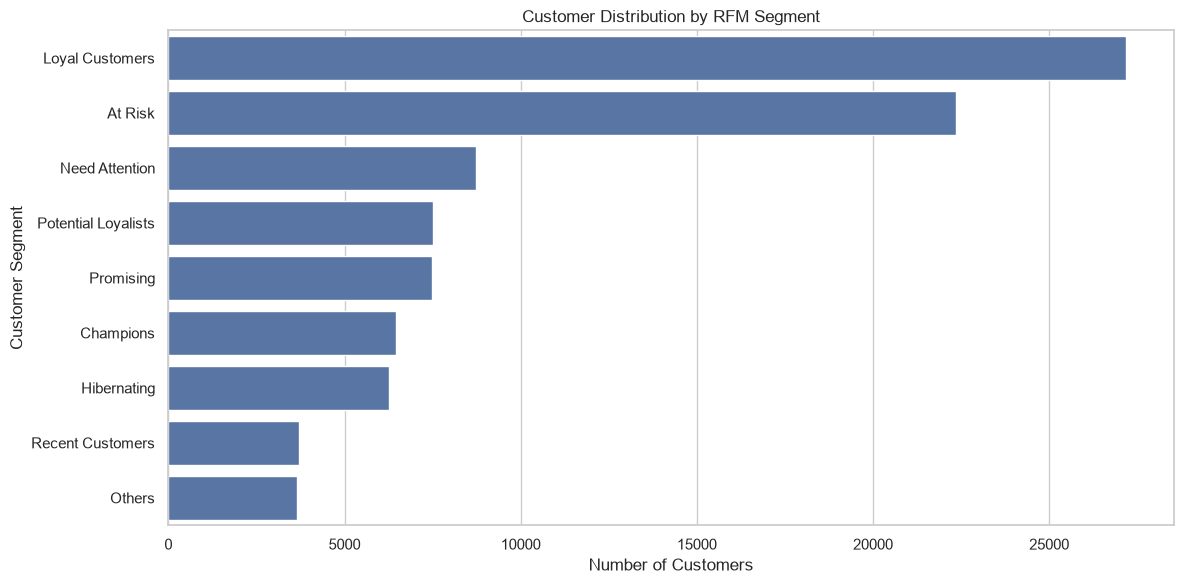

In [29]:
# Customer count by segment
plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="customers",
    y="customer_segment"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

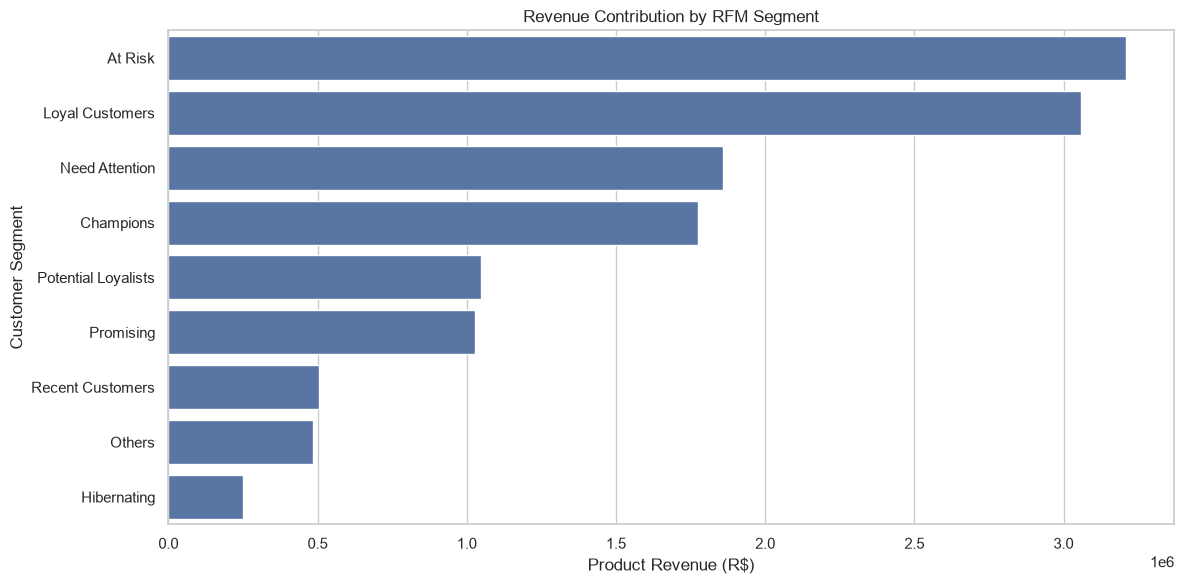

In [30]:
# Revenue contribution by segment
plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary.sort_values(
        "revenue", ascending=False
    ),
    x="revenue",
    y="customer_segment"
)

plt.title("Revenue Contribution by RFM Segment")
plt.xlabel("Product Revenue (R$)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

## 14. Customer Cohort Retention Analysis

Cohort analysis groups customers based on the month of their first delivered purchase. It tracks their purchasing activity in subsequent months to understand customer retention.

In [31]:
# Keep delivered orders and customer identifiers
cohort_data = customer_orders[
    ["customer_unique_id", "order_id", "order_purchase_timestamp"]
].copy()

# Convert purchase dates to monthly periods
cohort_data["order_month"] = (
    cohort_data["order_purchase_timestamp"].dt.to_period("M")
)

# Identify each customer's first purchase month
cohort_data["cohort_month"] = (
    cohort_data.groupby("customer_unique_id")["order_month"]
    .transform("min")
)

# Calculate months since first purchase
cohort_data["months_since_first_purchase"] = (
    (cohort_data["order_month"].dt.year
     - cohort_data["cohort_month"].dt.year) * 12
    + (cohort_data["order_month"].dt.month
       - cohort_data["cohort_month"].dt.month)
)

display(cohort_data.head())

print("Total purchase records:", len(cohort_data))
print("Number of customer cohorts:",
      cohort_data["cohort_month"].nunique())

,customer_unique_id,order_id,order_purchase_timestamp,order_month,cohort_month,months_since_first_purchase
0,7c396fd4830fd04220f754e42b4e5bff,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10,2017-09,1
1,af07308b275d755c9edb36a90c618231,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07,2018-07,0
2,3a653a41f6f9fc3d2a113cf8398680e8,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08,2018-08,0
3,7c142cf63193a1473d2e66489a9ae977,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-11,2017-11,0
4,72632f0f9dd73dfee390c9b22eb56dd6,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02,2018-02,0


Total purchase records: 96478
Number of customer cohorts: 23


In [32]:
# Count distinct active customers in each cohort and month
cohort_activity = (
    cohort_data.groupby(
        ["cohort_month", "months_since_first_purchase"]
    )["customer_unique_id"]
    .nunique()
    .reset_index(name="active_customers")
)

# Calculate the original size of each cohort
cohort_sizes = (
    cohort_activity[
        cohort_activity["months_since_first_purchase"] == 0
    ][["cohort_month", "active_customers"]]
    .rename(columns={"active_customers": "cohort_customers"})
)

# Combine activity with cohort sizes
cohort_retention = cohort_activity.merge(
    cohort_sizes,
    on="cohort_month",
    how="left"
)

# Calculate retention percentage
cohort_retention["retention_rate_pct"] = (
    cohort_retention["active_customers"]
    / cohort_retention["cohort_customers"]
    * 100
)

display(cohort_retention.head(15))

,cohort_month,months_since_first_purchase,active_customers,cohort_customers,retention_rate_pct
0,2016-09,0,1,1,100.00
1,2016-10,0,262,262,100.00
2,2016-10,6,1,262,0.38
3,2016-10,9,1,262,0.38
4,2016-10,11,1,262,0.38
5,2016-10,13,1,262,0.38
6,2016-10,15,1,262,0.38
7,2016-10,17,1,262,0.38
8,2016-10,19,2,262,0.76
9,2016-10,20,2,262,0.76


In [33]:
# Get the first and last cohort months
first_month = cohort_data["cohort_month"].min()
last_month = cohort_data["order_month"].max()

# Create a complete grid of eligible cohort-month combinations
cohort_grid = []

for cohort_month in sorted(cohort_data["cohort_month"].unique()):
    max_month = (
        (last_month.year - cohort_month.year) * 12
        + last_month.month - cohort_month.month
    )

    for month_number in range(max_month + 1):
        cohort_grid.append({
            "cohort_month": cohort_month,
            "months_since_first_purchase": month_number
        })

cohort_grid = pd.DataFrame(cohort_grid)

# Add cohort sizes
cohort_grid = cohort_grid.merge(
    cohort_sizes,
    on="cohort_month",
    how="left"
)

# Add monthly active customers
cohort_retention_complete = cohort_grid.merge(
    cohort_activity,
    on=["cohort_month", "months_since_first_purchase"],
    how="left"
)

# Fill months with no returning customers
cohort_retention_complete["active_customers"] = (
    cohort_retention_complete["active_customers"].fillna(0)
)

# Calculate retention percentage
cohort_retention_complete["retention_rate_pct"] = (
    cohort_retention_complete["active_customers"]
    / cohort_retention_complete["cohort_customers"]
    * 100
)

# Display results
display(cohort_retention_complete.head(20))

print("Total cohort records:",
      len(cohort_retention_complete))
print("Number of cohorts:",
      cohort_retention_complete["cohort_month"].nunique())

,cohort_month,months_since_first_purchase,cohort_customers,active_customers,retention_rate_pct
0,2016-09,0,1,1.00,100.00
1,2016-09,1,1,0.00,0.00
2,2016-09,2,1,0.00,0.00
3,2016-09,3,1,0.00,0.00
4,2016-09,4,1,0.00,0.00
5,2016-09,5,1,0.00,0.00
6,2016-09,6,1,0.00,0.00
7,2016-09,7,1,0.00,0.00
8,2016-09,8,1,0.00,0.00
9,2016-09,9,1,0.00,0.00


Total cohort records: 278
Number of cohorts: 23


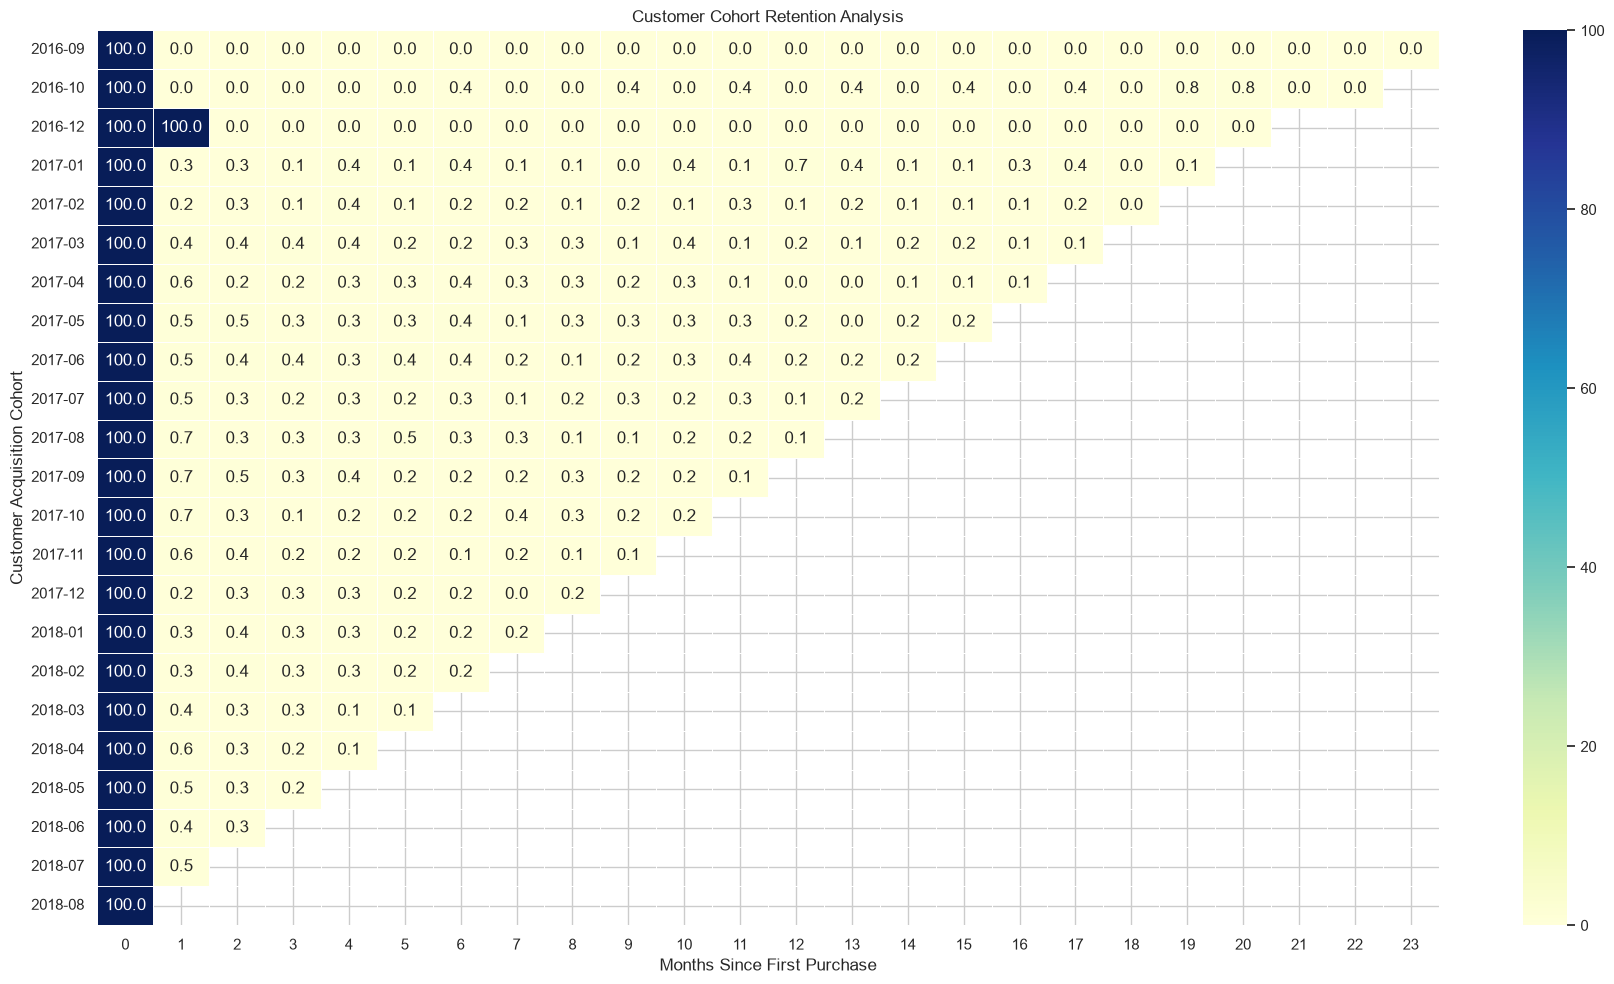

In [34]:
# Create retention matrix
retention_matrix = cohort_retention_complete.pivot(
    index="cohort_month",
    columns="months_since_first_purchase",
    values="retention_rate_pct"
)

# Plot heatmap
plt.figure(figsize=(18, 10))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100
)

plt.title("Customer Cohort Retention Analysis")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")
plt.tight_layout()
plt.show()

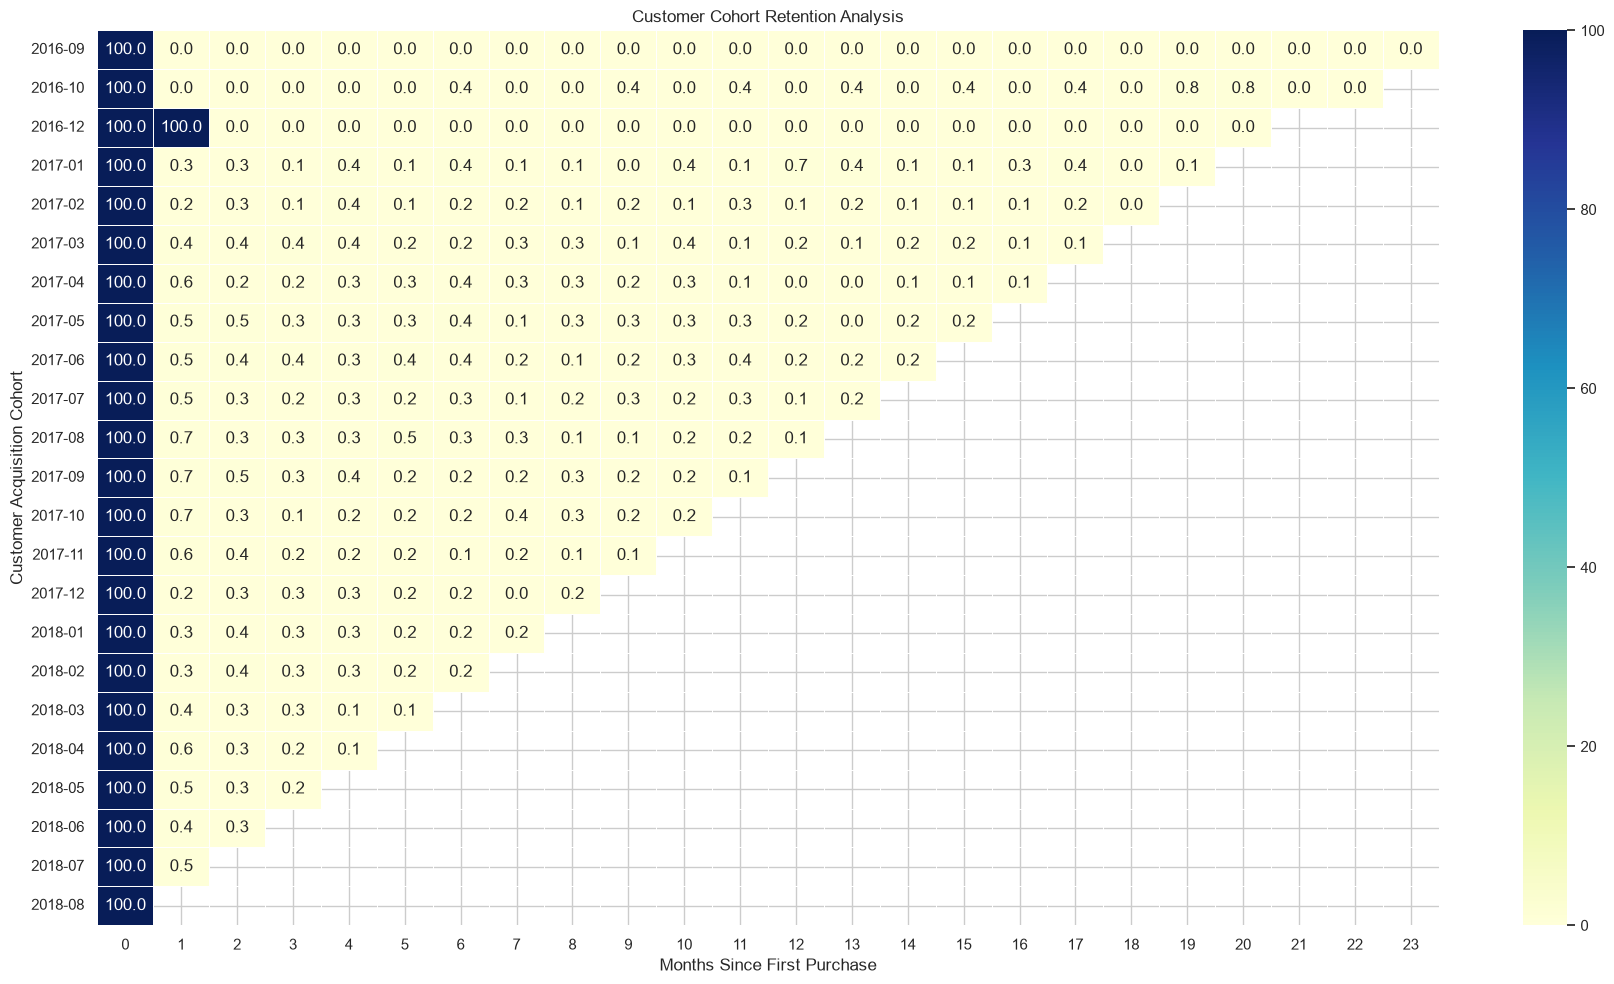

In [35]:
# Create retention matrix
retention_matrix = cohort_retention_complete.pivot(
    index="cohort_month",
    columns="months_since_first_purchase",
    values="retention_rate_pct"
)

# Plot heatmap
plt.figure(figsize=(18, 10))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100
)

plt.title("Customer Cohort Retention Analysis")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")
plt.tight_layout()
plt.show()

In [36]:
# Calculate weighted retention for the first three months
retention_summary = (
    cohort_retention_complete[
        cohort_retention_complete[
            "months_since_first_purchase"
        ].isin([1, 2, 3])
    ]
    .groupby("months_since_first_purchase")
    .agg(
        total_cohort_customers=("cohort_customers", "sum"),
        total_active_customers=("active_customers", "sum")
    )
    .reset_index()
)

retention_summary["weighted_retention_pct"] = (
    retention_summary["total_active_customers"]
    / retention_summary["total_cohort_customers"]
    * 100
)

display(retention_summary.round(2))

,months_since_first_purchase,total_cohort_customers,total_active_customers,weighted_retention_pct
0,1,87214,421.00,0.48
1,2,81265,273.00,0.34
2,3,75387,192.00,0.25


## 18. Key Findings and Conclusion

### Key Findings

1. The analysis covered 93,358 unique customers.
2. Approximately 97% of customers made only one delivered purchase.
3. Repeat customers represented approximately 3% of the customer base.
4. RFM analysis identified distinct customer groups, including Champions, Loyal Customers, At Risk, and Hibernating customers.
5. Cohort analysis showed low calendar-month repeat purchasing activity.
6. The cohort heatmap highlights differences in customer retention across acquisition months.

### Business Recommendations

1. Develop targeted campaigns to encourage one-time customers to purchase again.
2. Introduce loyalty rewards for repeat customers.
3. Create re-engagement campaigns for At Risk customers.
4. Provide personalized offers to high-value Champions.
5. Monitor cohort retention to evaluate the effectiveness of customer retention campaigns.

### Conclusion

This notebook used Python, Pandas, Matplotlib, and Seaborn to analyse customer purchasing behaviour, customer value, RFM segments, and cohort retention. The findings can help an e-commerce business identify valuable customers and develop strategies to improve customer retention.